# IMPORTS

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupShuffleSplit, train_test_split

from core.config import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    REGRESSION_ALWAYS,
    MASKED_COLUMNS,
    P_COLUMNS,
    P_LABEL_COLUMNS,
    CATALOGO_BOLT,
    N_P_LABEL_CLASSES,
)

from core.dataset import (
    Preprocessor,
    ConnectionDataset,
    validate_connection_targets,
)

from core.model import ConnectionDesignNet
from core.losses import ConnectionDesignLoss

from core.training import (
    fit,
    predict_loader,
    outputs_to_design,
)

from core.evaluation import (
    preparar_para_evaluar,
    evaluar_predicciones,
    evaluar_estructura,
    error_p_por_canto,
    evaluar_coherencia_prefijo,
)

In [3]:
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.width', 1000) 

# CONFIGURACIONES Y CARGA DE DATOS

In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", DEVICE)

Dispositivo: cpu


In [5]:
BATCH_SIZE = 64
EPOCHS = 200
LEARNING_RATE = 2e-2
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

HIDDEN_DIM = 192
NUM_BLOCKS = 3
DROPOUT = 0.10

In [6]:
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT = (
OUTPUT_DIR
/ "best_model_transiciones.pt"
)

print("Checkpoint:", BEST_CHECKPOINT.resolve())

Checkpoint: C:\Users\aarbona\OneDrive - Tecnicas Reunidas, S.A\Documentos\proyecto_uniones\V6\app\artifacts\best_model_transiciones.pt


In [7]:
DATA_PATH = Path("model_store/global_dataset.parquet")

In [8]:
if DATA_PATH.suffix.lower() == ".parquet":
    df = pd.read_parquet(DATA_PATH)

elif DATA_PATH.suffix.lower() == ".csv":
    df = pd.read_csv(DATA_PATH)

elif DATA_PATH.suffix.lower() in {".xlsx", ".xls"}:
    df = pd.read_excel(DATA_PATH)

else:
    raise ValueError(
        f"Formato no soportado: {DATA_PATH.suffix}"
    )

df = df.reset_index(drop=True)

print("Número de filas:", len(df))
print("Número de columnas:", len(df.columns))

display(df.head())

Número de filas: 3198
Número de columnas: 67


,Capacity_Moment,Capacity_Shear,Capacity_Axial,g,tws,Bp,tp,e,d,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,ts,tbs,tst,Hole,BEAM,COLUMN,DrawingCode,Bolt,SlipCritical,grado_acero,clase_tornillo,standard,BEAM_type,BEAM_d_mm,COLUMN_type,COLUMN_d_mm,fy_acero_mpa,fu_acero_mpa,fy_tornillo_mpa,fu_tornillo_mpa,fv_tornillo_mpa,n_cantonera,n_alma,Unicode,Lh,tornillo_1,tornillo_2,tornillo_3,tornillo_4,tornillo_5,tornillo_6,tornillo_7,tornillo_8,tornillo_9,tornillo_10,tornillo_11,p1_transition,p2_transition,p3_transition,p4_transition,p5_transition,p6_transition,p7_transition,p8_transition,p9_transition,p10_transition
0,298.57275,0.0000,0.0000,140,0,320,30,50,60.0,145.0,130.0,145.0,0.0,0.0,0,0,0,0,0,0,0,20,0,0,33,HEB300,HEB700,MLE,30,NO,S355JR,10.9,EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011,HE,300,HE,700,355,490,900,1000,500,0,2,MLE2364,0.00000,superior,viga primero,viga inferior,inferior,no_usado,no_usado,no_usado,no_usado,no_usado,no_usado,no_usado,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED
1,1348.03440,1065.5325,832.2975,155,0,300,30,50,65.0,155.0,85.0,140.0,140.0,140.0,160,135,135,85,200,0,0,15,15,15,33,HEA700,HEB700,MHE,30,YES,S355JR,A325M,AISC-360-05/10,HE,690,HE,700,355,490,660,830,372,4,5,MHE0176,557.72036,superior,viga primero,viga central,viga central,viga central,viga inferior,cantonera primero,cantonera central,cantonera central,cantonera inferior,inferior,superior__viga primero,viga primero__viga central,viga central__viga central,viga central__viga central,viga central__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera central,cantonera central__cantonera central,cantonera central__cantonera inferior,cantonera inferior__inferior
2,219.78000,0.0000,0.0000,105,0,240,25,40,40.0,90.0,110.0,150.0,110.0,0.0,0,0,0,0,0,0,0,12,10,0,22,HEA220,HEB500,MLE,20,NO,S355JR,10.9,AISC-360-05/10,HE,210,HE,500,355,490,900,1000,500,1,2,MOE6213,170.00000,superior,viga primero,viga inferior,cantonera central,inferior,no_usado,no_usado,no_usado,no_usado,no_usado,no_usado,superior__viga primero,viga primero__viga inferior,viga inferior__cantonera central,cantonera central__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED
3,591.07500,0.0000,0.0000,140,0,320,25,50,50.0,130.0,130.0,195.0,110.0,130.0,0,0,0,0,0,0,0,15,15,0,30,HEA340,HEB340,MHE,27,NO,S355JR,10.9,EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011,HE,330,HE,340,355,490,900,1000,500,2,2,MHE2248,265.00000,superior,viga primero,viga inferior,cantonera primero,cantonera inferior,inferior,no_usado,no_usado,no_usado,no_usado,no_usado,superior__viga primero,viga primero__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED
4,54.82000,97.1300,0.0000,90,0,220,15,40,39.0,85.0,60.0,85.0,0.0,0.0,0,0,0,0,0,0,0,10,10,0,22,HEA160,HEA320,MLE,20,NO,S355JR,10.9,AISC-360-05/10,HE,152,HE,310,355,490,900,1000,500,0,2,MLE6001,0.00000,superior,viga primero,viga inferior,inferior,no_usado,no_usado,no_usado,no_usado,no_usado,no_usado,no_usado,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED


# COMPROBACIONES

In [9]:
COLUMNAS_OBLIGATORIAS = (
    CATEGORICAL_FEATURES
    + NUMERIC_FEATURES
    + REGRESSION_ALWAYS
    + MASKED_COLUMNS
    + [
        "standard",
        "Bolt",
        "SlipCritical",
        "n_alma",
        "n_cantonera",
    ]
)

columnas_faltantes = [
    col
    for col in COLUMNAS_OBLIGATORIAS
    if col not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan columnas necesarias:\n"
        + "\n".join(columnas_faltantes)
    )

print("Todas las columnas obligatorias están presentes.")

Todas las columnas obligatorias están presentes.


In [10]:
p_labels_disponibles = all(
    col in df.columns
    for col in P_LABEL_COLUMNS
)

print("Existen p1_label...p12_label:", p_labels_disponibles)

if p_labels_disponibles:
    clases_p_label = sorted(
        pd.unique(
            df[P_LABEL_COLUMNS]
            .astype(str)
            .to_numpy()
            .ravel()
        )
    )

    print("Clases reales:")
    for clase in clases_p_label:
        print("  ", clase)

    print("Número de clases reales:", len(clases_p_label))
    print("N_P_LABEL_CLASSES configurado:", N_P_LABEL_CLASSES)

Existen p1_label...p12_label: False


# PREPARACIÓN

In [11]:
df_modelo = df.copy()

In [12]:
columnas_numericas = list(dict.fromkeys(
    NUMERIC_FEATURES
    + REGRESSION_ALWAYS
    + MASKED_COLUMNS
    + ["n_alma", "n_cantonera"]
))

for col in columnas_numericas:
    df_modelo[col] = pd.to_numeric(
        df_modelo[col],
        errors="coerce",
    )

In [13]:
df_modelo[MASKED_COLUMNS] = (
    df_modelo[MASKED_COLUMNS]
    .fillna(0.0)
)

In [14]:
columnas_sin_nulos = (
    CATEGORICAL_FEATURES
    + NUMERIC_FEATURES
    + REGRESSION_ALWAYS
    + [
        "standard",
        "Bolt",
        "SlipCritical",
        "n_alma",
        "n_cantonera",
    ]
)

n_antes = len(df_modelo)

df_modelo = (
    df_modelo
    .dropna(subset=columnas_sin_nulos)
    .reset_index(drop=True)
)

print("Filas iniciales:", n_antes)
print("Filas después de limpieza:", len(df_modelo))
print("Filas eliminadas:", n_antes - len(df_modelo))

Filas iniciales: 3198
Filas después de limpieza: 3198
Filas eliminadas: 0


In [15]:
p_values = (
    df_modelo[P_COLUMNS]
    .fillna(0.0)
    .to_numpy(dtype=float)
)

p_active = p_values > 0.0

p_activas_reales = p_active.sum(axis=1)

p_activas_esperadas = (
    df_modelo["n_alma"].astype(int).to_numpy()
    + df_modelo["n_cantonera"].astype(int).to_numpy()
    + 1
)

conteo_correcto = (
    p_activas_reales
    == p_activas_esperadas
)

posiciones = np.arange(len(P_COLUMNS))[None, :]

mascara_prefijo_esperada = (
    posiciones
    < p_activas_esperadas[:, None]
)

prefijo_correcto = np.all(
    p_active == mascara_prefijo_esperada,
    axis=1,
)

print(
    "Conteo de p correcto:",
    f"{100 * conteo_correcto.mean():.2f}%",
)

print(
    "Prefijo de p correcto:",
    f"{100 * prefijo_correcto.mean():.2f}%",
)

Conteo de p correcto: 100.00%
Prefijo de p correcto: 100.00%


In [16]:
filas_invalidas = ~(conteo_correcto & prefijo_correcto)

print("Filas inconsistentes:", filas_invalidas.sum())

if filas_invalidas.any():
    columnas_revision = (
        ["Unicode", "n_alma", "n_cantonera"]
        + P_COLUMNS
    )

    columnas_revision = [
        col for col in columnas_revision
        if col in df_modelo.columns
    ]

    display(
        df_modelo.loc[
            filas_invalidas,
            columnas_revision,
        ].head(20)
    )

Filas inconsistentes: 0


In [17]:
df_modelo = (
    df_modelo.loc[
        conteo_correcto & prefijo_correcto
    ]
    .reset_index(drop=True)
)

print("Filas disponibles para el modelo:", len(df_modelo))

Filas disponibles para el modelo: 3198


In [18]:
print("Valores de n_alma:")
display(
    df_modelo["n_alma"]
    .astype(int)
    .value_counts()
    .sort_index()
)

print("Valores de n_cantonera:")
display(
    df_modelo["n_cantonera"]
    .astype(int)
    .value_counts()
    .sort_index()
)

print("Valores de Bolt:")
display(
    df_modelo["Bolt"]
    .astype(str)
    .value_counts()
)

print("Valores de standard:")
display(
    df_modelo["standard"]
    .astype(str)
    .value_counts()
)

Valores de n_alma:


n_alma
1      41
2    1854
3    1118
4     168
5      17
Name: count, dtype: int64

Valores de n_cantonera:


n_cantonera
0    1484
1     419
2     971
3     289
4      35
Name: count, dtype: int64

Valores de Bolt:


Bolt
20    1046
24     779
30     672
27     544
16     115
22      36
36       6
Name: count, dtype: int64

Valores de standard:


standard
AISC-360-05/10                               1740
EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011    1219
CSA S16-09                                    239
Name: count, dtype: int64

In [19]:
bolt_numerico = (
    df_modelo["Bolt"]
    .astype(str)
    .str.replace("M", "", regex=False)
    .astype(int)
)

bolts_fuera_catalogo = sorted(
    set(bolt_numerico)
    - set(CATALOGO_BOLT)
)

print("Bolt fuera del catálogo:", bolts_fuera_catalogo)

if bolts_fuera_catalogo:
    raise ValueError(
        "Existen diámetros Bolt no incluidos en CATALOGO_BOLT."
    )


Bolt fuera del catálogo: []


# TRAIN - TEST

In [20]:
GROUP_COLUMN = (
    "Unicode"
    if "Unicode" in df_modelo.columns
    else None
)

print("Columna de agrupación:", GROUP_COLUMN)

Columna de agrupación: Unicode


In [21]:
if GROUP_COLUMN is not None:
    splitter_test = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED,
    )

    train_val_idx, test_idx = next(
        splitter_test.split(
            df_modelo,
            groups=df_modelo[GROUP_COLUMN],
        )
    )

    df_train_val = (
        df_modelo.iloc[train_val_idx]
        .reset_index(drop=True)
    )

    df_test = (
        df_modelo.iloc[test_idx]
        .reset_index(drop=True)
    )

    splitter_val = GroupShuffleSplit(
        n_splits=1,
        test_size=0.1765,
        random_state=SEED,
    )

    train_idx, val_idx = next(
        splitter_val.split(
            df_train_val,
            groups=df_train_val[GROUP_COLUMN],
        )
    )

    df_train = (
        df_train_val.iloc[train_idx]
        .reset_index(drop=True)
    )

    df_val = (
        df_train_val.iloc[val_idx]
        .reset_index(drop=True)
    )

In [22]:
print("Train:", len(df_train))
print("Validación:", len(df_val))
print("Test:", len(df_test))

print(
    "Total:",
    len(df_train) + len(df_val) + len(df_test),
)

Train: 2238
Validación: 480
Test: 480
Total: 3198


In [23]:
if GROUP_COLUMN is not None:
    grupos_train = set(df_train[GROUP_COLUMN])
    grupos_val = set(df_val[GROUP_COLUMN])
    grupos_test = set(df_test[GROUP_COLUMN])

    assert grupos_train.isdisjoint(grupos_val)
    assert grupos_train.isdisjoint(grupos_test)
    assert grupos_val.isdisjoint(grupos_test)

    print("No existe solapamiento de grupos.")

No existe solapamiento de grupos.


In [24]:
pre = Preprocessor()
pre.fit(df_train)

print(
    "Cardinalidades categóricas:",
    pre.cat_cardinalities,
)

print(
    "Número de clases standard:",
    pre.n_standard_classes,
)

print(
    "Clases standard:",
    list(pre.standard_encoder.classes_),
)

print(
    "Clases p_label:",
    pre.p_label_classes,
)

Cardinalidades categóricas: [3, 4, 1, 2]
Número de clases standard: 3
Clases standard: ['AISC-360-05/10', 'CSA S16-09', 'EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011']
Clases p_label: None


In [25]:
if pre.p_label_classes is not None:
    print(
        "Número real de clases p_label:",
        len(pre.p_label_classes),
    )

    print(
        "Número configurado en el modelo:",
        N_P_LABEL_CLASSES,
    )

    if len(pre.p_label_classes) != N_P_LABEL_CLASSES:
        print(
            "AVISO: no se entrenará p_label en este baseline."
        )

In [26]:
def comprobar_categorias_desconocidas(
    train_df,
    other_df,
    categorical_columns,
    nombre_split,
):
    problemas = {}

    for col in categorical_columns:
        train_values = set(
            train_df[col].astype(str).unique()
        )

        other_values = set(
            other_df[col].astype(str).unique()
        )

        desconocidas = sorted(
            other_values - train_values
        )

        if desconocidas:
            problemas[col] = desconocidas

    if problemas:
        print(
            f"Categorías desconocidas en {nombre_split}:"
        )

        for col, values in problemas.items():
            print(col, values)

    else:
        print(
            f"No hay categorías desconocidas en {nombre_split}."
        )

    return problemas

In [27]:
problemas_val = comprobar_categorias_desconocidas(
    df_train,
    df_val,
    CATEGORICAL_FEATURES,
    "validación",
)

problemas_test = comprobar_categorias_desconocidas(
    df_train,
    df_test,
    CATEGORICAL_FEATURES,
    "test",
)

No hay categorías desconocidas en validación.
No hay categorías desconocidas en test.


In [28]:
train_dataset = ConnectionDataset(
    df_train,
    pre,
)

val_dataset = ConnectionDataset(
    df_val,
    pre,
)

test_dataset = ConnectionDataset(
    df_test,
    pre,
)

In [29]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("Batches train:", len(train_loader))
print("Batches validación:", len(val_loader))
print("Batches test:", len(test_loader))

Batches train: 35
Batches validación: 8
Batches test: 8


In [30]:
batch = next(iter(train_loader))

for clave, valor in batch.items():
    print(
        f"{clave:30s}",
        tuple(valor.shape),
        valor.dtype,
    )

x_cat                          (64, 4) torch.int64
x_num                          (64, 10) torch.float32
standard_idx                   (64,) torch.int64
bolt_idx                       (64,) torch.int64
slip_critical                  (64,) torch.float32
n_alma_idx                     (64,) torch.int64
n_cantonera_idx                (64,) torch.int64
reg_always                     (64, 5) torch.float32
masked_value                   (64, 16) torch.float32
masked_mask                    (64, 16) torch.float32
p_label_idx                    (64, 12) torch.int64
p_transition_idx               (64, 12) torch.int64


# MODELO

In [31]:
model = ConnectionDesignNet(
    cat_cardinalities=pre.cat_cardinalities,
    num_continuous=len(NUMERIC_FEATURES),
    n_standard_classes=pre.n_standard_classes,
    hidden_dim=HIDDEN_DIM,
    num_blocks=NUM_BLOCKS,
    dropout=DROPOUT,
)

model = model.to(DEVICE)

print(model)

ConnectionDesignNet(
  (embeddings): ModuleList(
    (0): Embedding(3, 2)
    (1): Embedding(4, 2)
    (2): Embedding(1, 1)
    (3): Embedding(2, 1)
  )
  (input_layer): Sequential(
    (0): Linear(in_features=16, out_features=192, bias=True)
    (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (blocks): ModuleList(
    (0-2): 3 x ResNetBlock(
      (fc1): Linear(in_features=192, out_features=192, bias=True)
      (bn1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (fc2): Linear(in_features=192, out_features=192, bias=True)
      (bn2): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (activation): ReLU()
    )
  )
  (head_standard): Sequential(
    (0): Linear(in_features=192, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=3, bias=True)
  )
  (head_bolt): Seque

In [32]:
n_parametros = sum(
    p.numel()
    for p in model.parameters()
)

n_entrenables = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Parámetros totales: {n_parametros:,}")
print(f"Parámetros entrenables: {n_entrenables:,}")

Parámetros totales: 361,411
Parámetros entrenables: 361,411


In [33]:
criterion = ConnectionDesignLoss(
w_cls=1.0,
w_counts=1.0,
w_reg=1.0,
w_p_value=2.0,
w_stiffener_value=1.0,
w_masked_presence=0.5,

n_alma_weights=(
pre.count_class_weights["n_alma"]
),
n_cantonera_weights=(
pre.count_class_weights[
"n_cantonera"
]
),
presence_pos_weight=(
pre.presence_pos_weight
),

# Primeras 12 desviaciones:
# corresponden a p1...p12.
p_std_mm=pre.masked_std[:12],

p_tolerance_mm=10.0,
).to(DEVICE)

print(criterion)

ConnectionDesignLoss(
  (ce): CrossEntropyLoss()
  (bce): BCEWithLogitsLoss()
  (huber): SmoothL1Loss()
)


In [34]:
batch = next(iter(train_loader))

x_cat = batch["x_cat"].to(DEVICE)
x_num = batch["x_num"].to(DEVICE)

targets = {
    clave: valor.to(DEVICE)
    for clave, valor in batch.items()
    if clave not in ("x_cat", "x_num")
}

with torch.no_grad():
    predictions = model(x_cat, x_num)
    loss_prueba, partes_prueba = criterion(
        predictions,
        targets,
    )

print("Loss inicial:", float(loss_prueba))
print("Partes de la loss:")

for nombre, valor in partes_prueba.items():
    print(f"  {nombre:25s}: {valor:.4f}")

Loss inicial: 10.130613327026367
Partes de la loss:
  standard                 : 1.1562
  bolt                     : 1.9516
  slip_critical            : 0.7351
  n_alma                   : 2.1891
  n_cantonera              : 1.6059
  reg_always               : 0.5720
  p_value                  : 0.4111
  stiffener_value          : 0.5161
  masked_presence          : 1.1650
  p_within_10              : 0.2474


In [35]:
for nombre, valor in predictions.items():
    print(
        f"{nombre:35s}",
        tuple(valor.shape),
    )

standard_logits                     (64, 3)
bolt_logits                         (64, 7)
slip_critical_logit                 (64,)
n_alma_logits                       (64, 7)
n_cantonera_logits                  (64, 6)
reg_always                          (64, 5)
masked_value                        (64, 16)
masked_presence_logit               (64, 16)
p_transition_idx_used               (64, 12)


# ENTRENAMIENTO

In [36]:
history = fit(
model=model,
train_loader=train_loader,
val_loader=val_loader,
criterion=criterion,
device=DEVICE,
epochs=EPOCHS,
lr=LEARNING_RATE,
weight_decay=WEIGHT_DECAY,
log_every=5,
verbose=True,
checkpoint_path=BEST_CHECKPOINT,
)

epoch 001/200 | train=6.0925 | val=4.0975 | p_value=0.342 | p<=10mm=34.4% | stiffener=0.131 | presence=0.375 | n_alma=0.876 | n_cantonera=0.784 | MEJOR
epoch 002/200 | train=3.5147 | val=3.0167 | p_value=0.332 | p<=10mm=37.0% | stiffener=0.112 | presence=0.238 | n_alma=0.445 | n_cantonera=0.579 | MEJOR
epoch 003/200 | train=2.7854 | val=2.7389 | p_value=0.342 | p<=10mm=34.3% | stiffener=0.109 | presence=0.208 | n_alma=0.387 | n_cantonera=0.464 | MEJOR
epoch 005/200 | train=2.4181 | val=2.5543 | p_value=0.331 | p<=10mm=38.3% | stiffener=0.104 | presence=0.181 | n_alma=0.306 | n_cantonera=0.411 | MEJOR
epoch 007/200 | train=2.3781 | val=2.3864 | p_value=0.277 | p<=10mm=38.0% | stiffener=0.135 | presence=0.176 | n_alma=0.226 | n_cantonera=0.442 | MEJOR
epoch 010/200 | train=2.3986 | val=2.2566 | p_value=0.259 | p<=10mm=45.8% | stiffener=0.078 | presence=0.182 | n_alma=0.238 | n_cantonera=0.429 | MEJOR
epoch 013/200 | train=2.1914 | val=2.1252 | p_value=0.212 | p<=10mm=43.5% | stiffener=0.

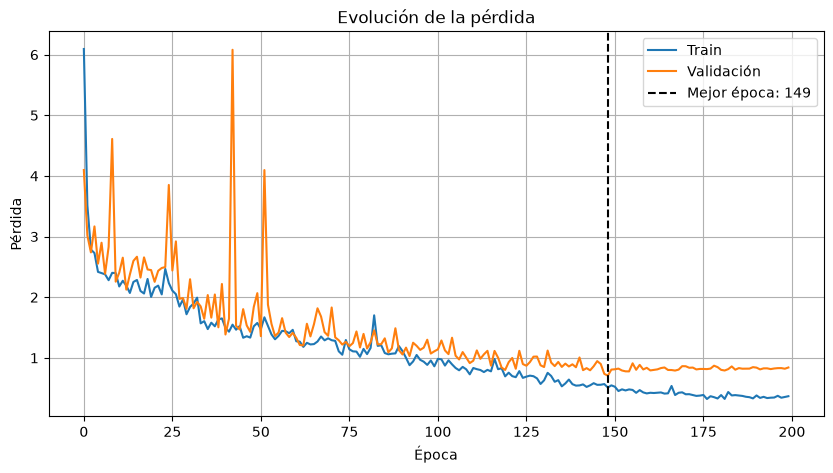

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    history["train_loss"],
    label="Train",
)

ax.plot(
    history["val_loss"],
    label="Validación",
)

ax.axvline(
    history["best_epoch"] - 1,
    color="black",
    linestyle="--",
    label=f"Mejor época: {history['best_epoch']}",
)

ax.set_xlabel("Época")
ax.set_ylabel("Pérdida")
ax.set_title("Evolución de la pérdida")
ax.legend()
ax.grid(True)

plt.show()

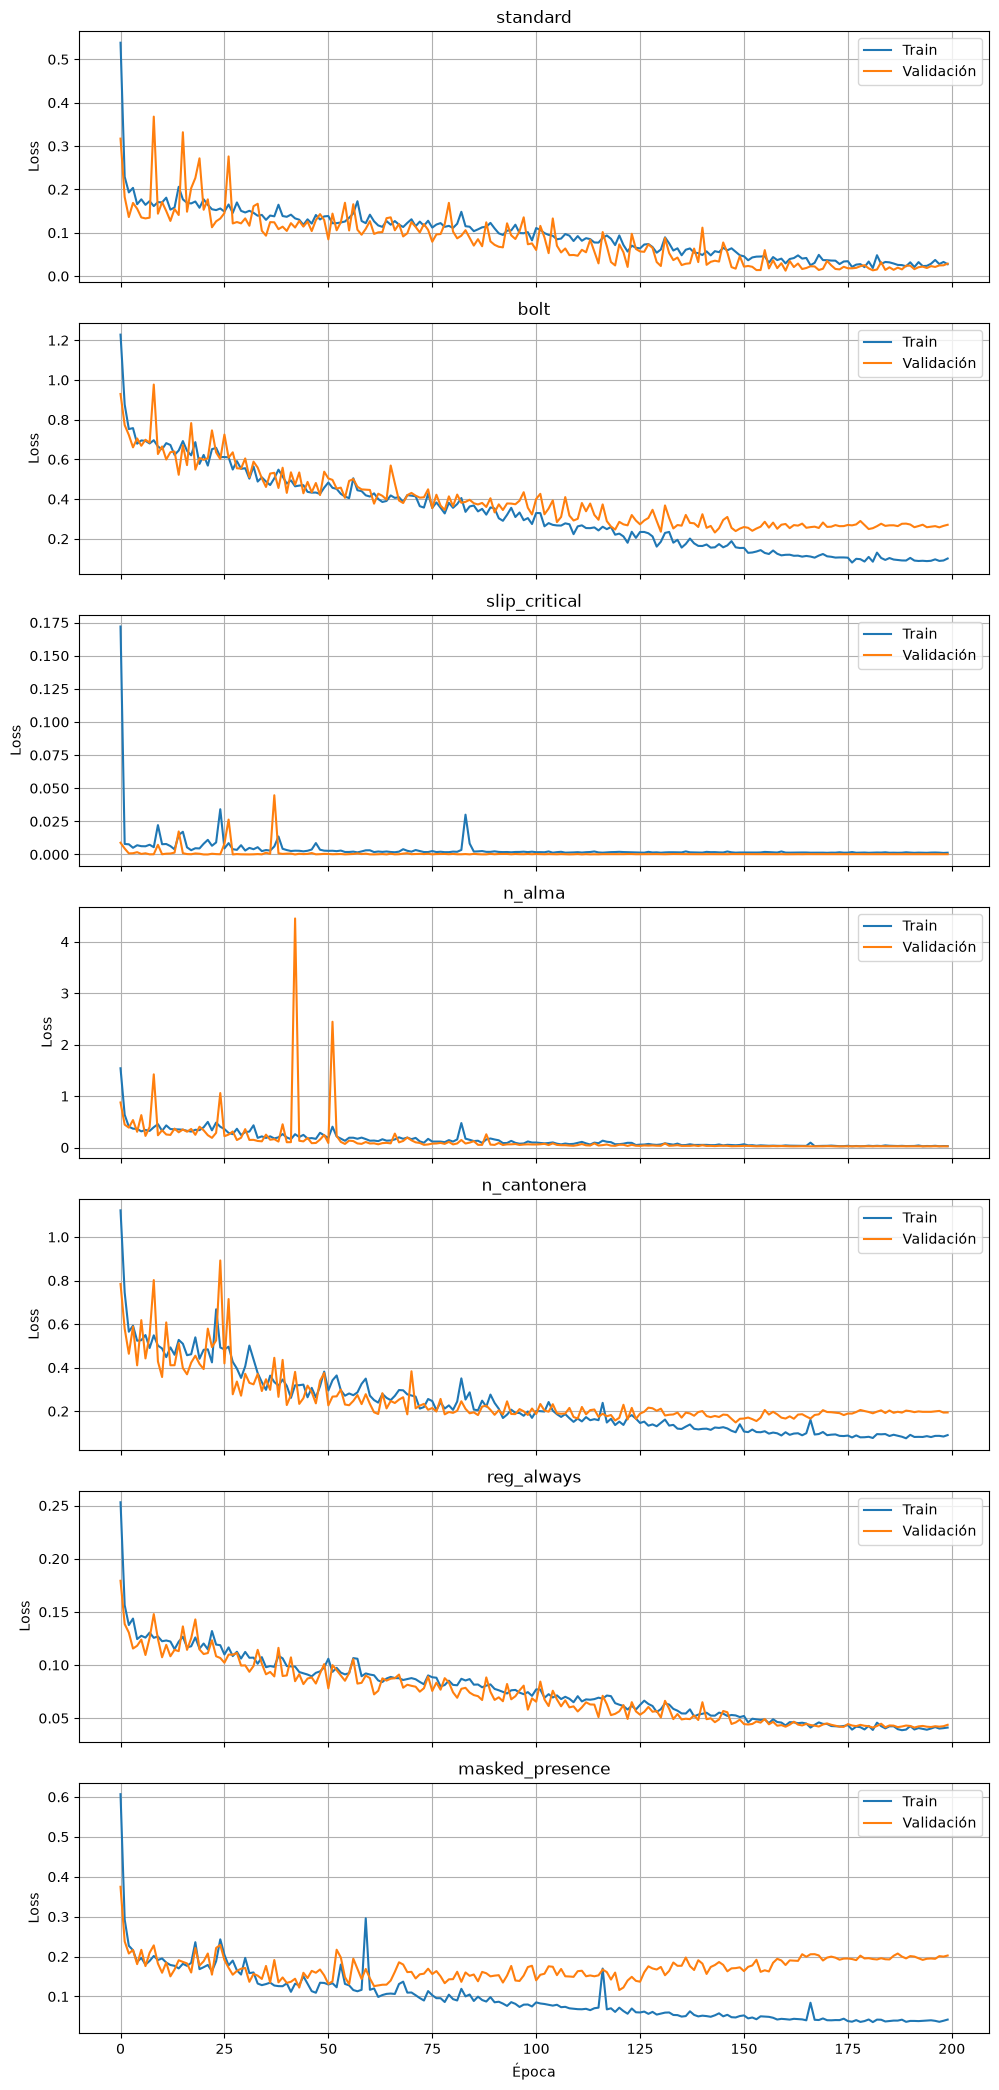

In [38]:
train_parts = pd.DataFrame(
    history["train_parts"]
)

val_parts = pd.DataFrame(
    history["val_parts"]
)

componentes = [
    "standard",
    "bolt",
    "slip_critical",
    "n_alma",
    "n_cantonera",
    "reg_always",
    "masked_value",
    "masked_presence",
]

componentes = [
    col for col in componentes
    if col in val_parts.columns
]

fig, axes = plt.subplots(
    nrows=len(componentes),
    ncols=1,
    figsize=(10, 3 * len(componentes)),
    sharex=True,
)

if len(componentes) == 1:
    axes = [axes]

for ax, componente in zip(axes, componentes):
    ax.plot(
        train_parts[componente],
        label="Train",
    )

    ax.plot(
        val_parts[componente],
        label="Validación",
    )

    ax.set_title(componente)
    ax.set_ylabel("Loss")
    ax.grid(True)
    ax.legend()

axes[-1].set_xlabel("Época")

plt.tight_layout()
plt.show()

In [39]:
p_within_10_por_epoca = [
    partes["p_within_10"]
    for partes in history["val_parts"]
]

mejor_indice_tolerancia = int(
    np.argmax(p_within_10_por_epoca)
)

mejor_epoca_tolerancia = (
    mejor_indice_tolerancia + 1
)

print(
    "Mejor época según % de p dentro de ±10 mm:",
    mejor_epoca_tolerancia
)

print(
    "Porcentaje dentro de ±10 mm:",
    f"{100 * p_within_10_por_epoca[mejor_indice_tolerancia]:.2f}%"
)

print(
    "Época seleccionada por val_loss:",
    history["best_epoch"]
)

Mejor época según % de p dentro de ±10 mm: 188
Porcentaje dentro de ±10 mm: 87.76%
Época seleccionada por val_loss: 149


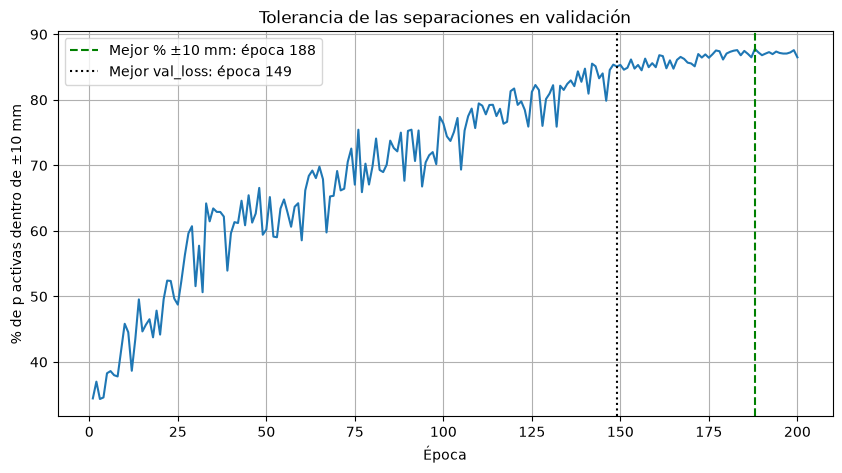

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(p_within_10_por_epoca) + 1),
    100 * np.asarray(p_within_10_por_epoca),
)

plt.axvline(
    mejor_epoca_tolerancia,
    color="green",
    linestyle="--",
    label=(
        "Mejor % ±10 mm: "
        f"época {mejor_epoca_tolerancia}"
    ),
)

plt.axvline(
    history["best_epoch"],
    color="black",
    linestyle=":",
    label=(
        "Mejor val_loss: "
        f"época {history['best_epoch']}"
    ),
)

plt.xlabel("Época")
plt.ylabel("% de p activas dentro de ±10 mm")
plt.title("Tolerancia de las separaciones en validación")
plt.grid(True)
plt.legend()
plt.show()

# TEST Y VALIDACIÓN

In [41]:
outputs_test = predict_loader(
model=model,
loader=test_loader,
device=DEVICE,
use_true_transitions=False,
)

full_design_test = outputs_to_design(
outputs_test,
pre,
)

In [42]:
outputs_test_topologia_real = predict_loader(
    model=model,
    loader=test_loader,
    device=DEVICE,
    use_true_transitions=True,
)

full_design_test_topologia_real = (
    outputs_to_design(
        outputs_test_topologia_real,
        pre,
    )
)

In [43]:
real_eval, pred_realista_eval = (
    preparar_para_evaluar(
        df_test,
        full_design_test,
    )
)

_, pred_topologia_real_eval = (
    preparar_para_evaluar(
        df_test,
        full_design_test_topologia_real,
    )
)

print("INFERENCIA REALISTA")
resultado_realista = evaluar_predicciones(
    real_eval,
    pred_realista_eval,
)

print("\nTOPOLOGÍA REAL")
resultado_techo = evaluar_predicciones(
    real_eval,
    pred_topologia_real_eval,
)

INFERENCIA REALISTA
                    EVALUACIÓN INTEGRAL DE PREDICCIONES Y TOLERANCIAS
Variable  N (Muestras)  MAE (mm)  RMSE (mm)  R2 Score  % Exacto (Catálogo)  % <= 5mm (Taller)  % <= 10mm (Taller)
       g           480      3.41       5.90     0.874                 52.7               88.3                94.6
       e           480      0.58       1.77     0.903                 88.8               99.6               100.0
       d           480      1.91       2.95     0.869                 23.3               91.9                98.5
      Bp           480      7.54      10.58     0.960                  3.8               48.1                79.0
      tp           480      1.00       2.37     0.801                 80.8               99.0                99.8
      p1           480      2.95       6.05     0.921                 62.7               88.1                95.6
      p2           480      6.83      16.02     0.776                 50.4               77.5                85.

In [44]:
for nombre, valor in outputs_test.items():
    print(
        f"{nombre:35s}",
        valor.shape,
    )

standard_logits                     (480, 3)
bolt_logits                         (480, 7)
slip_critical_logit                 (480,)
n_alma_logits                       (480, 7)
n_cantonera_logits                  (480, 6)
reg_always                          (480, 5)
masked_value                        (480, 16)
masked_presence_logit               (480, 16)
p_transition_idx_used               (480, 12)


In [45]:
full_design_test = outputs_to_design(
    outputs_test,
    pre,
)

print("Predicciones:", full_design_test.shape)

display(full_design_test.head())

Predicciones: (480, 42)


,g,e,d,Bp,tp,n_alma,n_cantonera,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,tws,ts,tbs,tst,Bolt,_bolt_nominal_mm,standard,SlipCritical,p1_transition,p2_transition,p3_transition,p4_transition,p5_transition,p6_transition,p7_transition,p8_transition,p9_transition,p10_transition,p11_transition,p12_transition,Hole,num_filas_tornillos,tiene_cantonera
0,135.0,40.0,50.873268,200.0,20.0,2,0,110.0,155.0,115.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,10.0,24,24,AISC-360-05/10,YES,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,26,4,False
1,140.0,50.0,56.643745,304.0,20.0,3,3,130.0,90.0,290.0,130.0,190.0,85.0,160.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,25.0,0.0,30,30,AISC-360-05/10,NO,superior__cantonera primero,cantonera primero__cantonera centro,cantonera centro__cantonera inferior,cantonera inferior__viga primero,viga primero__viga centro,viga centro__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,32,8,True
2,135.0,40.0,40.710701,221.0,20.0,2,0,110.0,100.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,24,24,EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011,NO,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,26,4,False
3,140.0,50.0,59.512405,324.0,30.0,3,0,150.0,115.0,115.0,150.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,30,30,EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011,NO,superior__viga primero,viga primero__viga centro,viga centro__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,32,5,False
4,100.0,40.0,40.659832,261.0,20.0,3,2,90.0,55.0,80.0,115.0,60.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,10.0,0.0,20,20,AISC-360-05/10,NO,superior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__viga primero,viga primero__viga centro,viga centro__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,22,7,True


In [46]:
p_pred = (
    full_design_test[P_COLUMNS]
    .fillna(0.0)
    .to_numpy(dtype=float)
)

p_pred_active = p_pred > 0.0

n_p_pred_esperadas = (
    full_design_test["n_alma"]
    .astype(int)
    .to_numpy()
    + full_design_test["n_cantonera"]
    .astype(int)
    .to_numpy()
    + 1
)

expected_mask = (
    np.arange(len(P_COLUMNS))[None, :]
    < n_p_pred_esperadas[:, None]
)

prefijo_pred_correcto = np.all(
    p_pred_active == expected_mask,
    axis=1,
)

print(
    "Diseños con prefijo correcto:",
    f"{100 * prefijo_pred_correcto.mean():.2f}%",
)

if not prefijo_pred_correcto.all():
    indices_malos = np.where(
        ~prefijo_pred_correcto
    )[0]

    display(
        full_design_test.iloc[indices_malos][
            ["n_alma", "n_cantonera"] + P_COLUMNS
        ].head(20)
    )

Diseños con prefijo correcto: 100.00%


## EVALUACIÓN NUMÉRICA

In [47]:
df_real_eval, df_pred_eval = preparar_para_evaluar(
    df_test,
    full_design_test,
)

resultados_regresion = evaluar_predicciones(
    df_real=df_real_eval,
    df_pred=df_pred_eval,
    tol_taller=(10.0, 20.0),
)

                    EVALUACIÓN INTEGRAL DE PREDICCIONES Y TOLERANCIAS
Variable  N (Muestras)  MAE (mm)  RMSE (mm)  R2 Score  % Exacto (Catálogo)  % <= 10mm (Taller)  % <= 20mm (Taller)
       g           480      3.41       5.90     0.874                 52.7                94.6                99.0
       e           480      0.58       1.77     0.903                 88.8               100.0               100.0
       d           480      1.91       2.95     0.869                 23.3                98.5               100.0
      Bp           480      7.54      10.58     0.960                  3.8                79.0                94.8
      tp           480      1.00       2.37     0.801                 80.8                99.8               100.0
      p1           480      2.95       6.05     0.921                 62.7                95.6                98.8
      p2           480      6.83      16.02     0.776                 50.4                85.2                93.1
      p3  

In [48]:
display(
    resultados_regresion
    .sort_values(
        "MAE (mm)",
        ascending=False,
    )
    .reset_index(drop=True)
)

,Variable,N (Muestras),MAE (mm),RMSE (mm),R2 Score,% Exacto (Catálogo),% <= 10mm (Taller),% <= 20mm (Taller)
0,p6,143,12.72,32.47,0.596,44.1,86.7,88.8
1,p7,58,10.86,31.69,0.348,51.7,91.4,91.4
2,p5,222,10.01,24.16,0.611,34.7,86.5,90.5
3,p4,337,9.98,25.40,0.672,38.9,86.1,91.4
4,p3,472,9.75,18.12,0.868,26.3,82.8,87.9
5,Bp,480,7.54,10.58,0.960,3.8,79.0,94.8
6,p2,480,6.83,16.02,0.776,50.4,85.2,93.1
7,tws,8,5.00,6.56,-1.616,25.0,100.0,100.0
8,p8,24,3.75,6.45,0.965,54.2,91.7,100.0
9,g,480,3.41,5.90,0.874,52.7,94.6,99.0


In [49]:
resultados_sesgo = []

for col in P_COLUMNS:
    real = (
        pd.to_numeric(df_test[col], errors="coerce")
        .fillna(0.0)
        .to_numpy(dtype=float)
    )

    pred = (
        pd.to_numeric(full_design_test[col], errors="coerce")
        .fillna(0.0)
        .to_numpy(dtype=float)
    )

    active = real > 0.0

    if active.sum() == 0:
        continue

    error = pred[active] - real[active]

    errores_negativos = error[error < 0]

    resultados_sesgo.append({
        "Variable": col,
        "N": int(active.sum()),
        "Real media (mm)": real[active].mean(),
        "Pred media (mm)": pred[active].mean(),
        "MAE (mm)": np.abs(error).mean(),
        "Sesgo (mm)": error.mean(),
        "% subestimadas": 100 * np.mean(error < 0),
        "% subestimadas > 5 mm": 100 * np.mean(error < -5),
        "% subestimadas > 10 mm": 100 * np.mean(error < -10),
        "Subestimación media (mm)": (
            -errores_negativos.mean()
            if len(errores_negativos) > 0
            else 0.0
        ),
    })

tabla_sesgo = pd.DataFrame(resultados_sesgo)

display(
    tabla_sesgo.round(2)
)

,Variable,N,Real media (mm),Pred media (mm),MAE (mm),Sesgo (mm),% subestimadas,% subestimadas > 5 mm,% subestimadas > 10 mm,Subestimación media (mm)
0,p1,480,113.54,114.17,2.95,0.63,14.17,5.42,2.08,8.18
1,p2,480,96.00,98.69,6.83,2.69,13.75,6.88,5.42,15.07
2,p3,472,137.10,137.96,9.75,0.86,25.00,13.35,9.53,17.79
3,p4,337,130.40,128.71,9.98,-1.69,22.85,12.17,8.90,25.53
4,p5,222,115.99,113.15,10.01,-2.84,19.37,12.61,9.01,33.16
5,p6,143,134.19,127.90,12.72,-6.29,18.88,11.89,9.79,50.33
6,p7,58,130.43,124.57,10.86,-5.86,10.34,8.62,6.90,80.83
7,p8,24,135.62,136.88,3.75,1.25,12.50,8.33,4.17,10.00
8,p9,4,167.50,165.00,2.50,-2.50,25.00,25.00,0.00,10.00


In [50]:
registros = []

for i in range(1, 13):
    col_p = f"p{i}"
    col_transition = f"p{i}_transition"

    if col_transition not in df_test.columns:
        continue

    real = (
        pd.to_numeric(df_test[col_p], errors="coerce")
        .fillna(0.0)
        .to_numpy(dtype=float)
    )

    pred = (
        pd.to_numeric(full_design_test[col_p], errors="coerce")
        .fillna(0.0)
        .to_numpy(dtype=float)
    )

    transiciones = (
        df_test[col_transition]
        .fillna("UNUSED")
        .astype(str)
        .to_numpy()
    )

    active = real > 0.0

    for indice in np.where(active)[0]:
        registros.append({
            "numero_p": i,
            "transicion": transiciones[indice],
            "Bolt": str(df_test.iloc[indice]["Bolt"]),
            "real_mm": real[indice],
            "pred_mm": pred[indice],
            "error_mm": pred[indice] - real[indice],
            "error_absoluto_mm": abs(
                pred[indice] - real[indice]
            ),
        })

errores_transicion = pd.DataFrame(registros)

In [51]:
resumen_transicion = (
    errores_transicion
    .groupby("transicion")
    .agg(
        N=("error_mm", "size"),
        real_media_mm=("real_mm", "mean"),
        pred_media_mm=("pred_mm", "mean"),
        MAE_mm=("error_absoluto_mm", "mean"),
        sesgo_mm=("error_mm", "mean"),
        subestimadas_pct=(
            "error_mm",
            lambda x: 100 * (x < 0).mean()
        ),
        subestimadas_mas_10_pct=(
            "error_mm",
            lambda x: 100 * (x < -10).mean()
        ),
    )
    .reset_index()
    .sort_values(
        ["subestimadas_mas_10_pct", "MAE_mm"],
        ascending=False,
    )
)

display(resumen_transicion.round(2))

,transicion,N,real_media_mm,pred_media_mm,MAE_mm,sesgo_mm,subestimadas_pct,subestimadas_mas_10_pct
12,viga inferior__cantonera primero,217,162.22,157.49,12.32,-4.73,38.71,16.59
9,viga central__viga central,30,176.63,174.17,8.13,-2.47,46.67,13.33
10,viga central__viga inferior,194,142.99,143.97,12.63,0.98,32.47,10.82
4,cantonera primero__cantonera central,58,170.41,169.22,7.22,-1.19,32.76,10.34
3,cantonera inferior__inferior,217,138.39,130.25,12.75,-8.14,16.13,9.68
2,cantonera central__inferior,68,118.46,114.04,7.50,-4.41,16.18,7.35
14,viga primero__viga central,194,92.24,98.35,10.70,6.11,18.56,6.70
5,cantonera primero__cantonera inferior,159,81.34,84.09,9.42,2.74,10.69,6.29
11,viga inferior__cantonera central,68,132.72,131.54,5.44,-1.18,16.18,5.88
15,viga primero__viga inferior,278,98.78,99.15,4.33,0.38,10.79,4.68


In [52]:
conteos_p_split = []

for nombre, split in {
    "train": df_train,
    "validacion": df_val,
    "test": df_test,
}.items():

    for col in P_COLUMNS:
        n_activos = (
            pd.to_numeric(
                split[col],
                errors="coerce",
            )
            .fillna(0.0)
            .gt(0)
            .sum()
        )

        conteos_p_split.append({
            "split": nombre,
            "p": col,
            "n_activos": int(n_activos),
        })

tabla_conteos_p = (
    pd.DataFrame(conteos_p_split)
    .pivot(
        index="p",
        columns="split",
        values="n_activos",
    )
)

display(tabla_conteos_p)

split,test,train,validacion
p,,,
p1,480,2238,480
p10,0,9,3
p11,0,0,0
p12,0,0,0
p2,480,2238,480
p3,472,2213,472
p4,337,1552,343
p5,222,926,190
p6,143,531,115


## EVALUACIÓN ESTRUCTURA TORNILLOS

In [53]:
metricas_estructura, confusion_filas = evaluar_estructura(
    test_df=df_test,
    full_design=full_design_test,
)


ESTRUCTURA DE FILAS DE TORNILLOS
n_alma exacto (%)              : 97.3
n_cantonera exacto (%)         : 92.3
num_filas exacto (%)           : 90.8
num_filas ±1 (%)               : 96.0

Número de filas: real frente a predicho:
predicho  3    4    5   6   7   8   9   10
real                                      
3          8    0    0   0   0   0   0   0
4          0  124    8   2   1   0   0   0
5          0    3  103   3   4   2   0   0
6          0    0    5  72   2   0   0   0
7          0    3    5   1  75   1   0   0
8          0    0    0   2   2  30   0   0
9          0    0    0   0   0   0  20   0
10         0    0    0   0   0   0   0   4


In [54]:
display(
    pd.Series(
        metricas_estructura,
        name="valor",
    ).to_frame()
)

,valor
n_alma_exacto,0.972917
n_cantonera_exacto,0.922917
num_filas_exacto,0.908333
num_filas_mas_menos_1,0.960417


In [55]:
display(confusion_filas)

predicho,3,4,5,6,7,8,9,10
real,,,,,,,,
3,8,0,0,0,0,0,0,0
4,0,124,8,2,1,0,0,0
5,0,3,103,3,4,2,0,0
6,0,0,5,72,2,0,0,0
7,0,3,5,1,75,1,0,0
8,0,0,0,2,2,30,0,0
9,0,0,0,0,0,0,20,0
10,0,0,0,0,0,0,0,4


## ERROR DE LAS P SEGÚN CANTO DE VIGA

In [56]:
tabla_error_canto = error_p_por_canto(
    test_df=df_test,
    full_design=full_design_test,
    n_bins=4,
)

MAE de las p activas por canto:
                    p1     p2     p3     p4     p5      p6      p7    p8   p9  p10  p11  p12  N_conexiones
BEAM_d_mm                                                                                                 
(113.999, 210.0]  1.44   2.62   5.32   8.49  34.17  100.00     NaN   NaN  NaN  NaN  NaN  NaN           132
(210.0, 270.0]    2.10   4.68   9.56   8.62  12.72    9.58  120.00   NaN  NaN  NaN  NaN  NaN           124
(270.0, 360.0]    3.96  13.72  14.26  14.43   9.13   19.29   52.50   NaN  NaN  NaN  NaN  NaN           105
(360.0, 690.0]    4.62   7.67  10.58   8.48   7.41    9.54    7.36  3.75  2.5  NaN  NaN  NaN           119


In [57]:
display(tabla_error_canto)

,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,N_conexiones
BEAM_d_mm,,,,,,,,,,,,,
"(113.999, 210.0]",1.44,2.62,5.32,8.49,34.17,100.00,NaN,NaN,NaN,NaN,NaN,NaN,132
"(210.0, 270.0]",2.10,4.68,9.56,8.62,12.72,9.58,120.00,NaN,NaN,NaN,NaN,NaN,124
"(270.0, 360.0]",3.96,13.72,14.26,14.43,9.13,19.29,52.50,NaN,NaN,NaN,NaN,NaN,105
"(360.0, 690.0]",4.62,7.67,10.58,8.48,7.41,9.54,7.36,3.75,2.5,NaN,NaN,NaN,119


## EVALUACIÓN DE LAS P EN GENERAL

In [58]:
p_real = (
    df_test[P_COLUMNS]
    .fillna(0.0)
    .to_numpy(dtype=float)
)

p_pred = (
    full_design_test[P_COLUMNS]
    .fillna(0.0)
    .to_numpy(dtype=float)
)

p_mask_real = p_real > 0.0

error_p = np.abs(
    p_real[p_mask_real]
    - p_pred[p_mask_real]
)

resumen_global_p = pd.Series({
    "n_separaciones_activas": len(error_p),
    "MAE_p_mm": error_p.mean(),
    "RMSE_p_mm": np.sqrt(np.mean(error_p ** 2)),
    "error_mediano_mm": np.median(error_p),
    "percentil_90_error_mm": np.quantile(error_p, 0.90),
    "percentil_95_error_mm": np.quantile(error_p, 0.95),
    "porcentaje_error_hasta_5_mm": 100 * np.mean(error_p <= 5),
    "porcentaje_error_hasta_10_mm": 100 * np.mean(error_p <= 10),
    "porcentaje_error_hasta_20_mm": 100 * np.mean(error_p <= 20),
})

display(
    resumen_global_p.to_frame("valor")
)

,valor
n_separaciones_activas,2220.000000
MAE_p_mm,7.851619
RMSE_p_mm,19.599465
error_mediano_mm,5.000000
percentil_90_error_mm,15.000000
percentil_95_error_mm,40.000000
porcentaje_error_hasta_5_mm,78.963964
porcentaje_error_hasta_10_mm,87.567568
porcentaje_error_hasta_20_mm,92.477477


## SESGO DE SEPARACIÓN

In [59]:
error_firmado_p = (
    p_pred[p_mask_real]
    - p_real[p_mask_real]
)

resumen_sesgo_p = pd.Series({
    "sesgo_medio_mm": error_firmado_p.mean(),
    "sesgo_mediano_mm": np.median(error_firmado_p),
    "porcentaje_subestimadas": (
        100 * np.mean(error_firmado_p < 0)
    ),
    "porcentaje_sobreestimadas": (
        100 * np.mean(error_firmado_p > 0)
    ),
    "subestimacion_media_mm": (
        -error_firmado_p[error_firmado_p < 0].mean()
        if np.any(error_firmado_p < 0)
        else 0.0
    ),
})

display(
    resumen_sesgo_p.to_frame("valor")
)

,valor
sesgo_medio_mm,-0.189640
sesgo_mediano_mm,0.000000
porcentaje_subestimadas,18.423423
porcentaje_sobreestimadas,37.252252
subestimacion_media_mm,21.823465


## ERROR Y SESGO POR P

In [60]:
resultados_por_p = []

for col in P_COLUMNS:
    real = (
        pd.to_numeric(
            df_test[col],
            errors="coerce",
        )
        .fillna(0.0)
        .to_numpy()
    )

    pred = (
        pd.to_numeric(
            full_design_test[col],
            errors="coerce",
        )
        .fillna(0.0)
        .to_numpy()
    )

    active = real > 0.0

    if not active.any():
        continue

    error = pred[active] - real[active]

    resultados_por_p.append({
        "p": col,
        "n": int(active.sum()),
        "real_media_mm": real[active].mean(),
        "pred_media_mm": pred[active].mean(),
        "MAE_mm": np.abs(error).mean(),
        "sesgo_mm": error.mean(),
        "subestimadas_pct": 100 * np.mean(error < 0),
        "error_p90_mm": np.quantile(
            np.abs(error),
            0.90,
        ),
    })

resultados_por_p = pd.DataFrame(
    resultados_por_p
)

display(resultados_por_p)

,p,n,real_media_mm,pred_media_mm,MAE_mm,sesgo_mm,subestimadas_pct,error_p90_mm
0,p1,480,113.535833,114.166667,2.949583,0.630833,14.166667,10.00000
1,p2,480,95.999167,98.687500,6.832500,2.688333,13.750000,15.00000
2,p3,472,137.100000,137.955508,9.749576,0.855508,25.000000,25.00000
3,p4,337,130.396416,128.709199,9.978330,-1.687217,22.848665,15.25788
4,p5,222,115.992828,113.153153,10.007645,-2.839675,19.369369,15.00000
5,p6,143,134.188811,127.902098,12.720280,-6.286713,18.881119,43.00000
6,p7,58,130.431034,124.568966,10.862069,-5.862069,10.344828,10.00000
7,p8,24,135.625000,136.875000,3.750000,1.250000,12.500000,10.00000
8,p9,4,167.500000,165.000000,2.500000,-2.500000,25.000000,7.00000


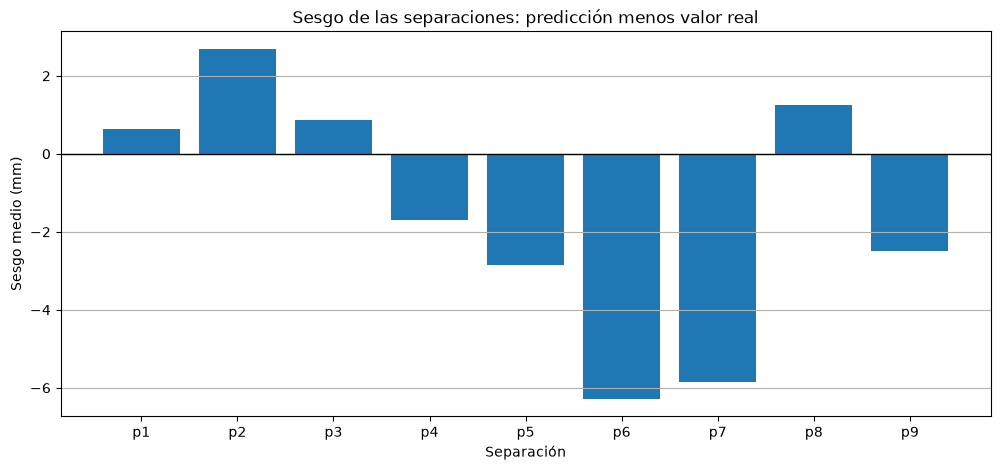

In [61]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    resultados_por_p["p"],
    resultados_por_p["sesgo_mm"],
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_xlabel("Separación")
ax.set_ylabel("Sesgo medio (mm)")
ax.set_title(
    "Sesgo de las separaciones: predicción menos valor real"
)

ax.grid(True, axis="y")

plt.show()

## COMPARACIÓN EJEMPLOS

In [62]:
columnas_comparacion = [
    "n_alma",
    "n_cantonera",
    "Bolt",
] + P_COLUMNS

In [63]:
comparacion = pd.concat(
    [
        df_test[columnas_comparacion]
        .reset_index(drop=True)
        .add_suffix("_real"),

        full_design_test[columnas_comparacion]
        .reset_index(drop=True)
        .add_suffix("_pred"),
    ],
    axis=1,
)

display(comparacion.head(20))

,n_alma_real,n_cantonera_real,Bolt_real,p1_real,p2_real,p3_real,p4_real,p5_real,p6_real,p7_real,p8_real,p9_real,p10_real,p11_real,p12_real,n_alma_pred,n_cantonera_pred,Bolt_pred,p1_pred,p2_pred,p3_pred,p4_pred,p5_pred,p6_pred,p7_pred,p8_pred,p9_pred,p10_pred,p11_pred,p12_pred
0,2,0,24,110.0,150.0,110.0,0.0,0.0,0,0,0,0,0,0,0,2,0,24,110.0,155.0,115.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,3,3,30,135.0,85.0,295.0,135.0,185.0,85,165,0,0,0,0,0,3,3,30,130.0,90.0,290.0,130.0,190.0,85.0,160.0,0.0,0.0,0.0,0.0,0.0
2,2,0,24,110.0,100.0,110.0,0.0,0.0,0,0,0,0,0,0,0,2,0,24,110.0,100.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0,30,150.0,110.0,110.0,150.0,0.0,0,0,0,0,0,0,0,3,0,30,150.0,115.0,115.0,150.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,3,2,20,90.0,55.0,75.0,110.0,55.0,110,0,0,0,0,0,0,3,2,20,90.0,55.0,80.0,115.0,60.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0
5,3,2,27,130.0,95.0,95.0,170.0,110.0,130,0,0,0,0,0,0,3,2,27,135.0,115.0,140.0,180.0,115.0,130.0,0.0,0.0,0.0,0.0,0.0,0.0
6,4,3,27,115.0,75.0,170.0,170.0,105.0,235,75,125,0,0,0,0,4,3,30,100.0,75.0,170.0,175.0,105.0,235.0,75.0,130.0,0.0,0.0,0.0,0.0
7,2,0,27,120.0,100.0,120.0,0.0,0.0,0,0,0,0,0,0,0,2,0,27,115.0,105.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,3,2,20,100.0,55.0,230.0,245.0,55.0,125,0,0,0,0,0,0,3,2,20,105.0,55.0,225.0,230.0,60.0,135.0,0.0,0.0,0.0,0.0,0.0,0.0
9,3,2,30,145.0,85.0,145.0,205.0,85.0,180,0,0,0,0,0,0,3,2,30,150.0,85.0,145.0,210.0,85.0,180.0,0.0,0.0,0.0,0.0,0.0,0.0


In [64]:
error_por_conexion = np.zeros(len(df_test))

for col in P_COLUMNS:
    real = (
        df_test[col]
        .fillna(0.0)
        .to_numpy(dtype=float)
    )

    pred = (
        full_design_test[col]
        .fillna(0.0)
        .to_numpy(dtype=float)
    )

    active = real > 0.0

    error_por_conexion += (
        np.abs(real - pred) * active
    )

indices_peores = np.argsort(
    error_por_conexion
)[::-1][:20]

display(
    comparacion.iloc[indices_peores]
)

,n_alma_real,n_cantonera_real,Bolt_real,p1_real,p2_real,p3_real,p4_real,p5_real,p6_real,p7_real,p8_real,p9_real,p10_real,p11_real,p12_real,n_alma_pred,n_cantonera_pred,Bolt_pred,p1_pred,p2_pred,p3_pred,p4_pred,p5_pred,p6_pred,p7_pred,p8_pred,p9_pred,p10_pred,p11_pred,p12_pred
84,3,2,20,105.0,55.0,170.0,185.0000,55.0000,90,0,0,0,0,0,0,2,0,20,120.0,175.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
167,3,2,20,105.0,55.0,155.0,180.0000,55.0000,90,0,0,0,0,0,0,2,0,24,120.0,170.0,115.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
90,3,2,20,110.0,55.0,220.0,240.0000,55.0000,140,0,0,0,0,0,0,3,0,30,145.0,115.0,120.0,145.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
317,3,2,20,110.0,55.0,220.0,240.0000,55.0000,140,0,0,0,0,0,0,3,0,30,145.0,115.0,120.0,145.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
141,3,3,20,90.0,90.0,205.0,90.0000,160.0000,55,110,0,0,0,0,0,2,2,20,100.0,195.0,110.0,115.0,130.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
417,3,3,27,120.0,75.0,175.0,120.0000,95.0000,75,145,0,0,0,0,0,3,2,30,135.0,105.0,125.0,195.0,120.0,150.0,0.0,0.0,0.0,0.0,0.0,0.0
100,3,3,16,75.0,75.0,140.0,75.0000,120.0000,45,95,0,0,0,0,0,2,2,20,90.0,190.0,100.0,135.0,105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34,3,2,20,100.0,55.0,135.0,165.0000,55.0000,120,0,0,0,0,0,0,2,2,20,110.0,80.0,200.0,75.0,125.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
118,3,2,24,110.0,70.0,155.0,190.0000,70.0000,135,0,0,0,0,0,0,3,0,30,145.0,100.0,110.0,145.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
191,3,2,16,75.0,45.0,70.0,100.0000,45.0000,90,0,0,0,0,0,0,2,0,20,95.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## EVALUACIÓN POR DIÁMETRO

In [65]:
evaluacion_bolt = []

bolt_real = (
    df_test["Bolt"]
    .astype(str)
    .str.replace("M", "", regex=False)
    .astype(int)
    .to_numpy()
)

for bolt in sorted(np.unique(bolt_real)):
    filas_bolt = bolt_real == bolt

    real_bolt = p_real[filas_bolt]
    pred_bolt = p_pred[filas_bolt]

    active_bolt = real_bolt > 0.0

    if not active_bolt.any():
        continue

    error = (
        pred_bolt[active_bolt]
        - real_bolt[active_bolt]
    )

    evaluacion_bolt.append({
        "Bolt": bolt,
        "n_conexiones": int(filas_bolt.sum()),
        "n_separaciones": int(active_bolt.sum()),
        "MAE_mm": np.abs(error).mean(),
        "sesgo_mm": error.mean(),
        "subestimadas_pct": 100 * np.mean(error < 0),
    })

evaluacion_bolt = pd.DataFrame(
    evaluacion_bolt
)

display(evaluacion_bolt)

,Bolt,n_conexiones,n_separaciones,MAE_mm,sesgo_mm,subestimadas_pct
0,16,17,57,20.263158,0.964912,15.789474
1,20,149,660,8.641651,-0.871212,12.575758
2,22,6,37,20.000000,-4.864865,29.729730
3,24,128,533,7.700010,-0.324578,18.949343
4,27,89,457,7.253829,0.733042,19.256018
5,30,89,460,5.028261,0.297826,24.130435
6,36,2,16,6.250000,-1.250000,37.500000
